# Overfitting & Underfitting

**Goal:** Understand the two failure modes of every ML model — and how to diagnose and fix them.

**Why it matters:**
- A model that fits training data perfectly but fails on new data is useless.
- Overfitting and underfitting are the two ends of a spectrum; finding the sweet spot is the core of ML engineering.
- Every technique you'll learn later (regularization, dropout, early stopping, data augmentation) exists to fight overfitting.

**Prerequisite:** [../03-supervised-learning/02-tree-randomforest.ipynb](../03-supervised-learning/02-tree-randomforest.ipynb)

**Dataset:** Synthetic + Titanic (for real-world demonstration)

# بیش‌ پردازش  و کم‌ پردازش 

**هدف:** درک دو حالت شکست هر مدل یادگیری ماشین — و چگونگی تشخیص و رفع آن‌ها.

**چرا مهم است:**
- مدلی که داده‌ی آموزش را بی‌نقص پرازش می‌دهد اما روی داده‌ی جدید شکست می‌خورد، بی‌فایده است.
- بیش‌ پردازش و کم‌ پردازش دو سر یک طیف‌اند؛ پیدا کردن نقطه‌ی تعادل، هسته‌ی مهندسی یادگیری ماشین است.
- هر تکنیکی که بعداً یاد می‌گیری (regularization، dropout، early stopping، data augmentation) برای مقابله با بیش‌ پردازش وجود دارد.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.model_selection import (
    train_test_split, learning_curve, validation_curve,
)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
  accuracy_score, f1_score, roc_auc_score, mean_squared_error,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
np.random.seed(42)

print("Setup complete.")

Setup complete.


## The Three Regimes

| Regime | Train error | Test error | Cause | Fix |
|--------|-------------|------------|-------|-----|
| **Underfitting** | High | High | Model too simple | More features, more capacity, less regularization |
| **Good fit** | Low | Low | Balanced | — |
| **Overfitting** | Very low | High | Model too complex, too little data | More data, regularization, simpler model |

**The bias-variance decomposition:**

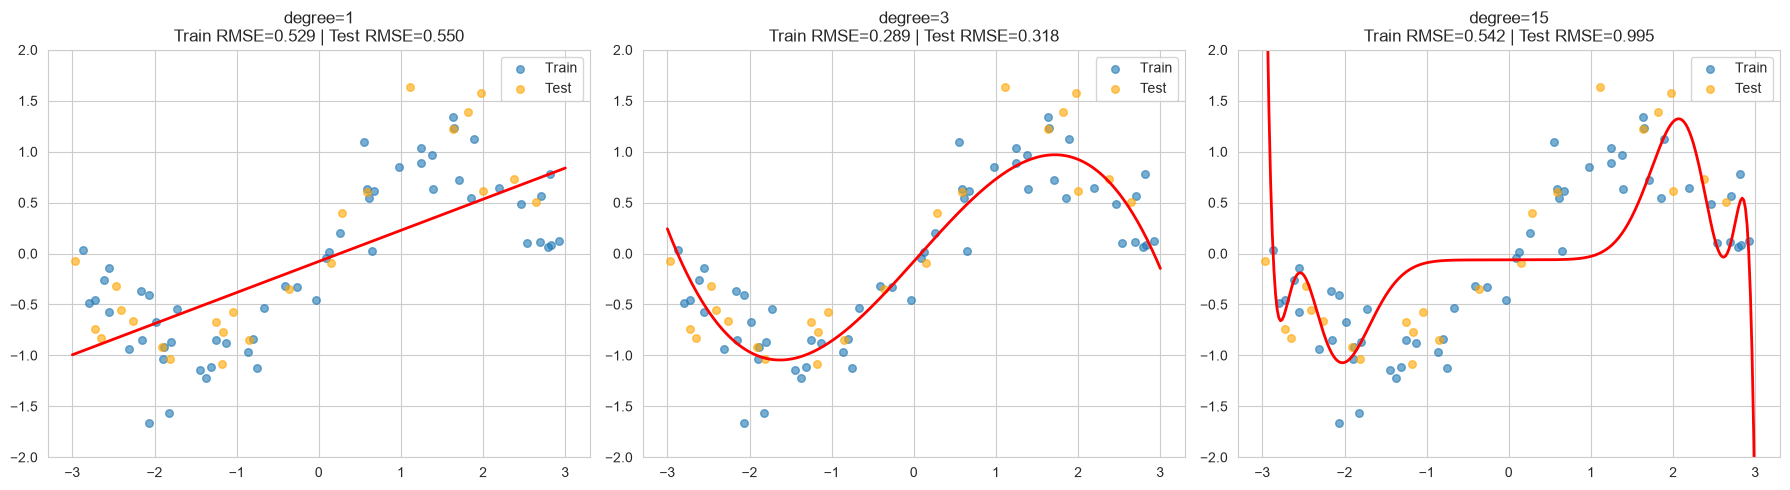

In [4]:
# Generate noisy non-linear data
np.random.seed(42)
n = 80
X_syn = np.sort(np.random.uniform(-3, 3, n)).reshape(-1, 1)
y_syn = np.sin(X_syn).ravel() + np.random.normal(0, 0.3, n)
# y = sin(x) + noise
# sin gives a smooth non-linear pattern.
# noise std=0.3 → moderate noise so overfitting is visible.

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_syn, y_syn, test_size=0.3, random_state=42
)

# Try polynomial degrees 1, 3, 15 — underfit / good / overfit
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

for ax, degree in zip(axes, [1, 3, 15]):
    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False,
    )
    X_tr_p = poly.fit_transform(X_train_s)
    X_te_p = poly.transform(X_test_s)
    X_plot_p = poly.transform(X_plot)

    model = LinearRegression()
    model.fit(X_tr_p, y_train_s)

    train_rmse = np.sqrt(mean_squared_error(y_train_s, model.predict(X_tr_p)))
    test_rmse = np.sqrt(mean_squared_error(y_test_s, model.predict(X_te_p)))

    ax.scatter(X_train_s, y_train_s, s=30, alpha=0.6, label="Train")
    ax.scatter(X_test_s, y_test_s, s=30, alpha=0.6, color="orange", label="Test")
    ax.plot(X_plot, model.predict(X_plot_p), "r-", linewidth=2)
    ax.set_title(f"degree={degree}\nTrain RMSE={train_rmse:.3f} | Test RMSE={test_rmse:.3f}")
    ax.set_ylim(-2, 2)
    ax.legend()

plt.tight_layout()
plt.show()

## Learning Curves — Diagnose Over/Underfitting

A **learning curve** plots train and validation error as a function of **training set size**.

**Patterns:**
- **Underfit:** both curves plateau at high error — more data won't help.
- **Good fit:** both curves converge to low error.
- **Overfit:** train error stays low, validation stays high with a large gap — more data WILL help.

**How to use it:**  
Fit a learning curve. If the gap is large, get more data or regularize. If both are high, add capacity.

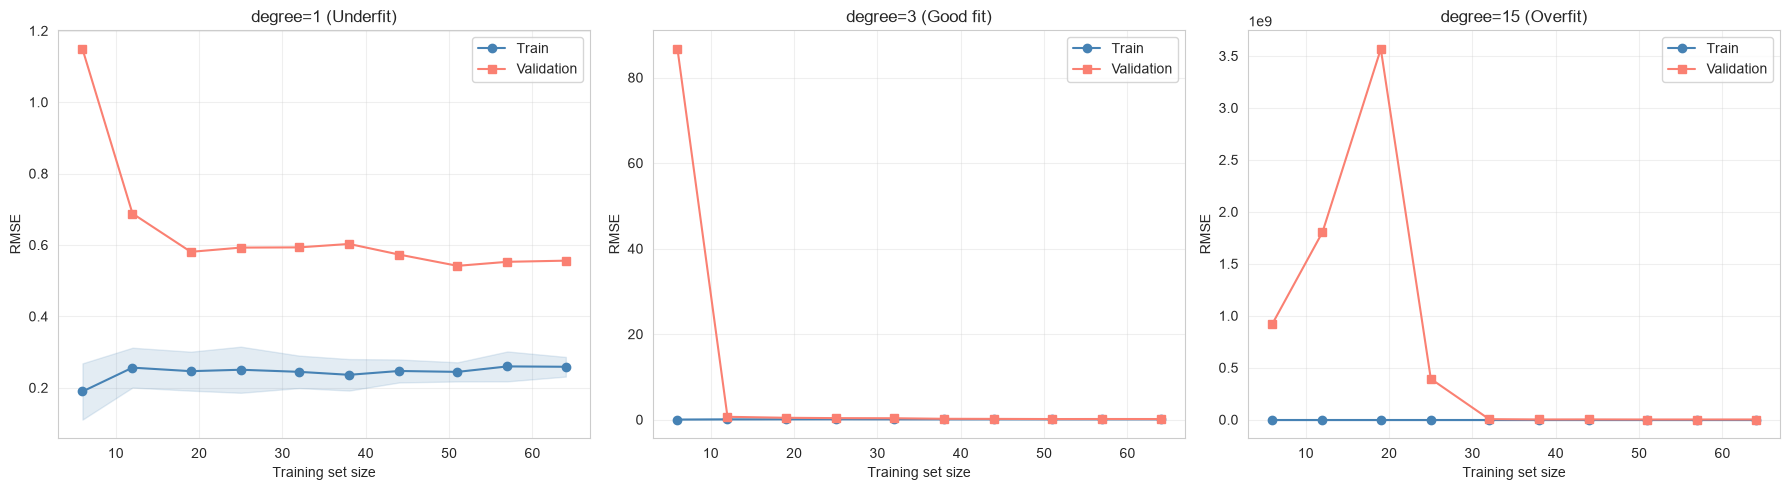

In [5]:
def plot_learning_curve(estimator, X, y, cv=5, title="Learning Curve"):
    """Convenience wrapper around sklearn's learning_curve."""
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y,
        cv=cv,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring="neg_mean_squared_error",
        n_jobs=-1,
        shuffle=True,
        random_state=42,
    )
    train_mean = -train_scores.mean(axis=1)
    val_mean = -val_scores.mean(axis=1)
    plt.plot(train_sizes, train_mean, "o-", color="steelblue", label="Train")
    plt.plot(train_sizes, val_mean,   "s-", color="salmon",    label="Validation")
    plt.fill_between(
        train_sizes,
        train_mean - train_scores.std(axis=1),
        train_mean + train_scores.std(axis=1),
        alpha=0.15, color="steelblue",
    )
    plt.xlabel("Training set size")
    plt.ylabel("RMSE")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, degree, name in zip(axes, [1, 3, 15], ["Underfit", "Good fit", "Overfit"]):
    plt.sca(ax)
    pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", LinearRegression()),
    ])
    plot_learning_curve(pipe, X_syn, y_syn, cv=5, title=f"degree={degree} ({name})")

plt.show()

## Validation Curves — Diagnose One Hyperparameter

A **validation curve** plots train and validation score as a function of **a single hyperparameter**.

**Patterns:**
- Left side of the plot → likely underfitting (high bias)
- Right side → likely overfitting (high variance)
- Best value → where validation score peaks

**Compared to learning curves:**  
- Learning curve → vary training size
- Validation curve → vary one hyperparameter

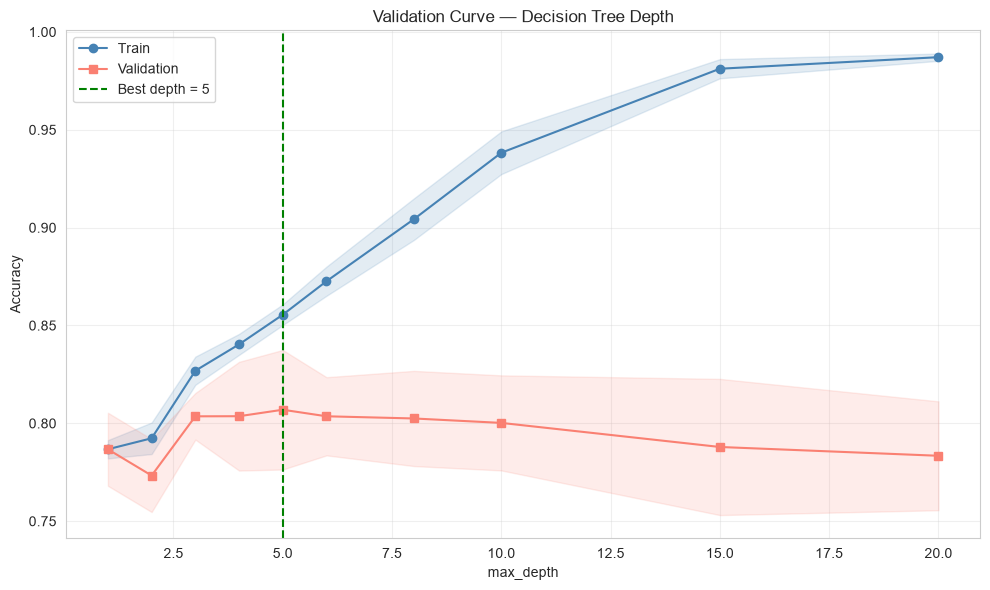

Best max_depth by validation: 5


In [6]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df["HasCabin"] = df["Cabin"].notna().astype(int)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda x: x.fillna(x.median()))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch",
         "Fare", "Embarked", "HasCabin", "FamilySize", "IsAlone"]]

X = df.drop(columns=["Survived"])
y = df["Survived"]

numeric_features = ["Age", "SibSp", "Parch", "Fare", "HasCabin", "FamilySize", "IsAlone"]
categorical_features = ["Pclass", "Sex", "Embarked"]

preprocessor = ColumnTransformer([
  ("num", SimpleImputer(strategy="median"), numeric_features),
  ("cat", Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", drop=None)),
  ]),categorical_features),
])

depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
train_scores, val_scores = validation_curve(
  Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(random_state=42)),
    ]),
    X, y,
    param_name="model__max_depth",
    param_range=depths,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(depths, train_mean, "o-", color="steelblue", label="Train")
plt.plot(depths, val_mean,   "s-", color="salmon",    label="Validation")
plt.fill_between(depths, train_mean - train_std, train_mean + train_std, alpha=0.15, color="steelblue")

plt.fill_between(depths, val_mean - val_std, val_mean + val_std, alpha=0.15, color="salmon")
plt.axvline(depths[int(np.argmax(val_mean))], color="green", linestyle="--",
            label=f"Best depth = {depths[int(np.argmax(val_mean))]}")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Validation Curve — Decision Tree Depth")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_depth = depths[int(np.argmax(val_mean))]
print(f"Best max_depth by validation: {best_depth}")





## Regularization as Anti-Overfitting

**Regularization** adds a penalty for model complexity.

- **L2 (Ridge):** `loss + α · Σw²`  
  Shrinks coefficients smoothly. Never exactly zero.
- **L1 (Lasso):** `loss + α · Σ|w|`  
  Can zero out coefficients → feature selection.
- **ElasticNet:** combines L1 + L2.

**α (alpha)** controls strength:
- α = 0 → no regularization (overfit risk)
- α small → mild
- α large → heavy (underfit risk)

**Same idea in trees:** `max_depth`, `min_samples_leaf`, `ccp_alpha`.
**Same idea in boosting:** `learning_rate`, `subsample`, `reg_alpha`, `reg_lambda`.



**Regularization** جریمه‌ای برای پیچیدگی مدل اضافه می‌کند.

- **L2 (Ridge):** `loss + α · Σw²`  
  ضرایب را به‌نرمی کوچک می‌کند. هرگز دقیقاً صفر نمی‌شوند.
- **L1 (Lasso):** `loss + α · Σ|w|`  
  می‌تواند ضرایب را صفر کند → انتخاب ویژگی.
- **ElasticNet:** ترکیب L1 + L2.

**α (alpha)** شدت را کنترل می‌کند:
- α = 0 → بدون regularization (خطر بیش‌ پردازش)
- α کوچک → ملایم
- α بزرگ → شدید (خطر کم‌ پردازش)

**همین ایده در درخت‌ها:** `max_depth`، `min_samples_leaf`، `ccp_alpha`.
**همین ایده در boosting:** `learning_rate`، `subsample`، `reg_alpha`، `reg_lambda`.

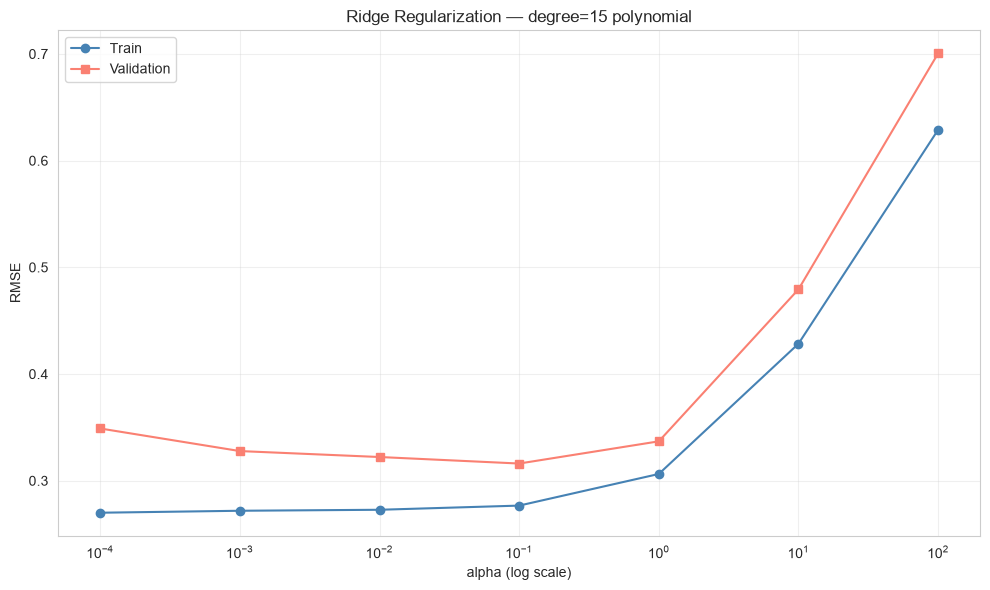

In [7]:
np.random.seed(42)
X_syn = np.sort(np.random.uniform(-3, 3, 100)).reshape(-1, 1)
y_syn = np.sin(X_syn).ravel() + np.random.normal(0, 0.3, 100)

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
train_rmse, val_rmse = [], []

for a in alphas:
    pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=15, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge(
            alpha=a,
            random_state=42,
        )),
    ])
    pipe.fit(X_train_s, y_train_s)
    train_rmse.append(np.sqrt(mean_squared_error(y_train_s, pipe.predict(X_train_s))))
    val_rmse.append(np.sqrt(mean_squared_error(y_test_s,  pipe.predict(X_test_s))))

plt.figure(figsize=(10, 6))
plt.plot(alphas, train_rmse, "o-", label="Train", color="steelblue")
plt.plot(alphas, val_rmse,   "s-", label="Validation", color="salmon")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("RMSE")
plt.title("Ridge Regularization — degree=15 polynomial")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Techniques to Fight Overfitting — Cheat Sheet

| Technique | Mechanism | When to use |
|-----------|-----------|-------------|
| **More data** | Averages out noise | Always if you can afford it |
| **Simpler model** | Fewer parameters | If variance dominates |
| **L1/L2 regularization** | Penalize large weights | Linear/logistic models |
| **Dropout** | Randomly zero activations | Neural networks |
| **Early stopping** | Stop before overfit | Neural nets, boosting |
| **Data augmentation** | More diverse samples | Images, text, audio |
| **Ensembling** | Average many models | Bagging, boosting, stacking |
| **Cross-validation** | Detect overfitting early | Always |

## Techniques to Fight Underfitting

| Technique | Mechanism |
|-----------|-----------|
| **More features** | Give the model more signal |
| **More complex model** | Higher capacity |
| **Less regularization** | Allow more fitting |
| **Better features** | Feature engineering |
| **Longer training** | If not converged yet |

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def evaluate(name, model):
    model.fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)
    test_acc  = model.score(X_test, y_test)
    gap = train_acc - test_acc
    return {"Model": name, "Train": train_acc, "Test": test_acc, "Gap": gap}

results = []
results.append(evaluate("Logistic (C=1)", Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])))

results.append(evaluate("Logistic (C=1000) — barely regularized", Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(C=1000, max_iter=1000, random_state=42)),
    # C=1000 → very weak regularization → more overfit risk
])))

results.append(evaluate("Tree (unlimited depth)", Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42)),
])))

results.append(evaluate("Tree (depth=4)", Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=4, random_state=42)),
])))

results.append(evaluate("Random Forest (200 trees)", Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
])))

comparison = pd.DataFrame(results).round(4)
print(comparison.to_string(index=False))


                                 Model  Train   Test     Gap
                        Logistic (C=1) 0.8132 0.8156 -0.0024
Logistic (C=1000) — barely regularized 0.8146 0.8156 -0.0010
                Tree (unlimited depth) 0.9860 0.7374  0.2485
                        Tree (depth=4) 0.8427 0.7933  0.0494
             Random Forest (200 trees) 0.9860 0.7933  0.1927


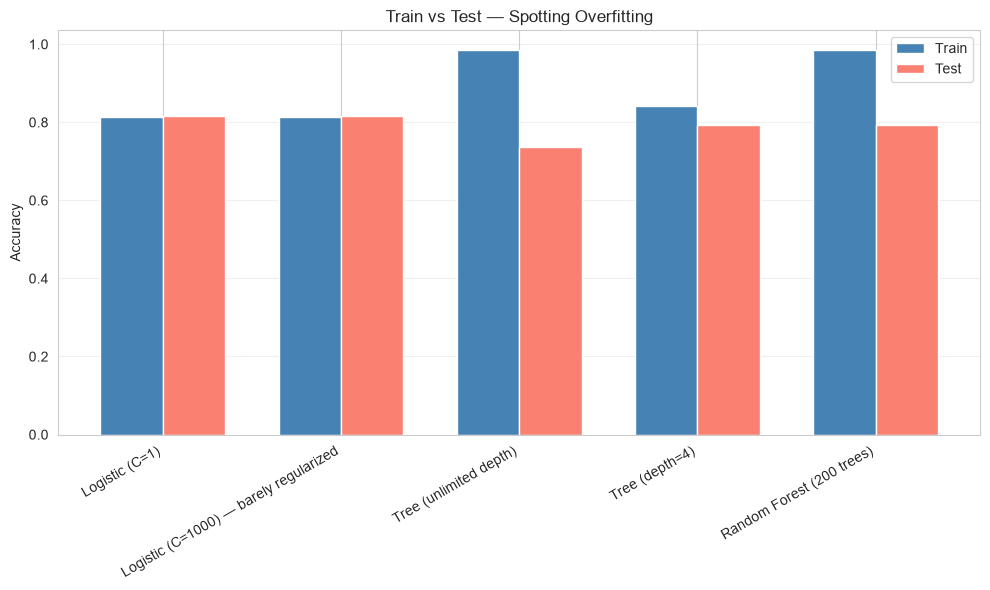

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(comparison))
width = 0.35

ax.bar(x - width/2, comparison["Train"], width, label="Train", color="steelblue")
ax.bar(x + width/2, comparison["Test"],  width, label="Test",  color="salmon")

ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=30, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Train vs Test — Spotting Overfitting")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Summary

### The three regimes
- **Underfit** — model too simple → high bias
- **Good fit** — balanced → best test performance
- **Overfit** — model too complex → high variance

### How to diagnose
- **Train >> Test gap** → overfit
- **Both high** → underfit
- **Learning curve** → tells you if more data will help
- **Validation curve** → tells you the best hyperparameter value

### How to fix
- Overfit → more data, simpler model, regularization, ensembling
- Underfit → more features, more capacity, less regularization

### The one rule
**Always watch the train/test gap.** A 1.0 train score with a 0.75 test score is a warning, not a trophy.

## 🚀 Next

→ [02-confusion-metrics.ipynb](./02-confusion-metrics.ipynb): beyond accuracy — precision, recall, F1, and when to use each.

In [10]:
import joblib
joblib.dump(preprocessor, "titanic_preprocessor.joblib")
print("Saved: titanic_preprocessor.joblib")

Saved: titanic_preprocessor.joblib
